# Get barcodes

## Luis

In [52]:
SCRATCH_PATH = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/"

input_file = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.gaf"
output_file = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv"
class Snakemake():
    def __init__(self):
        self.input = [input_file]
        self.output = [output_file]

snakemake = Snakemake()

In [53]:
# TODO: What is 15?
# TODO: Use chaining to make it cleaner
# TODO: Use the appropriate data types
import numpy as np
import pandas as pd

def get_barcode(barcode_list):
    '''
    Takes a list of elements of Path_matching and returns a corresponding 30-mer of 0s and 1s.
    '''
    return "".join(np.array(['ON' in element for element in barcode_list if 'BIT' in element], dtype=int).astype(str))

col_names = ['Query_name',
          'Query_length',
          'Query_start',
          'Query_end',
          'Strand',
          'Path_matching',
          'Path_length',
          'Start',
          'End',
          'Number_of_residue_matches',
          'Alignment_block_length',
          'Mapping_quality',
          'col_12',
          'col_13',
          'col_14',
          'col_15',
          'col_16']

snakemake_input = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.gaf'
snakemake_output = '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01_pd.tsv'

df = pd.read_csv(snakemake.input[0],
                  sep='\t',
                  names = col_names,
                  header = None,
                  usecols = ['Query_name', 'Strand', 'Path_matching'])#, 'Start', 'End', 'col_15'])
     
df = (df
      .drop_duplicates(subset = 'Query_name', keep = False) # This is to discard "chimeric" reads. Maybe they can be handled?
      
      .astype({'Strand': 'category'})#, 'Start': 'int32', 'End': 'int32'}) # Set dtypes
      
      .query("Path_matching.str.contains('SPACER2') and Path_matching.str.contains('Variant')") # Keep only complete reads. TODO Could this cause problems on future calls when chaining? MAYBE I NEED TO USE FUNCTIONS!
      
      .assign(#col_15 = df['col_15'].astype(str).str.split(':').str[-1].astype('float32'), # Format col 15
              Query_name = lambda df_: df_['Query_name'].str.replace(' ', '_'),
              # Query_name = df['Query_name'].astype(str).str.replace(' ', '_'),
              Strand = (lambda df_: df_['Strand']
                        .cat.set_categories(['+', '-'])
                        .mask(df_['Path_matching'].str.contains('<'), '-')
                       )
             )
     )

# Get barcodes. TODO: How to incorporate the logic on chain? 
# TODO CONSIDER SAVING THE LIST (path split) HERE! I AM REPEATING THE COMPUTATION TWICE
df.loc[df['Strand'] == '+', 'Barcode'] = (df
                                          .loc[df['Strand'] == '+','Path_matching']
                                          .str.split('>')
                                          .apply(get_barcode)
                                         )# Get barcode list

df.loc[df['Strand'] == '-', 'Barcode'] = (df.
                                          loc[df['Strand'] == '-','Path_matching']
                                          .str.split('<').str[::-1]
                                          .apply(get_barcode)
                                         )# Get barcode list

# df = df.loc[:, ['Query_name', 'Barcode', 'Strand', 'Start', 'End', 'Path_matching', 'col_15']] # Rearrange to match order of dictionary
# df = df.loc[:, ['Query_name', 'Barcode', 'Strand', 'Path_matching']] # Rearrange to match order of dictionary

df.to_csv(snakemake.output[0],
          sep='\t',
          index = False)

## D

In [54]:
SCRATCH_PATH = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/"

input_file = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_1_01.gaf"
output_file = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_1_01.tsv"
class Snakemake():
    def __init__(self):
        self.input = [input_file]
        self.output = [output_file]

snakemake = Snakemake()

In [56]:
import csv
import numpy as np

cigar_dict = {}
with open(snakemake.input[0], "r") as infile:
    for line in infile:
        data = line.split("\t")
        ##changed to include whole readname, whitespace replaced with underscore
        read_id = data[0].replace(" ", "_")
        if ">" in data[5]:
            cigar_dict[read_id] = (
                "+",
                int(data[7]),
                int(data[8]),
                data[5],
                data[15].split(":")[-1][:-1],
            )
        else:
            cigar_dict[read_id] = (
                "-",
                int(data[7]),
                int(data[8]),
                data[5],
                data[15].split(":")[-1][:-1],
            )

barcode_dict = {}
for key in cigar_dict.keys():
    cigar = cigar_dict[key]
    if "Variant" in cigar[3] and "SPACER2" in cigar[3]:
        if cigar[0] == "-":
            barcode = cigar[3].split("<")
            barcode = barcode[::-1]
        elif cigar[0] == "+":
            barcode = cigar[3].split(">")
        barcode = barcode[:-1]
        barcode = (
            np.array(["ON" in item for item in barcode if "BIT" in item])
            .astype(int)
            .astype(str)
            .tolist()
        )
        barcode = "".join(barcode)
        barcode_dict[key] = barcode

barcode_dict = [
    {"readname": key, "barcode": val, "cigar": cigar_dict[key]}
    for key, val in barcode_dict.items()
]

keys = ["readname", "barcode", "cigar"]
with open(snakemake.output[0], "w") as outfile:
    dict_writer = csv.DictWriter(outfile, keys, delimiter="\t")
    dict_writer.writeheader()
    dict_writer.writerows(barcode_dict)

# Set threshold

In [83]:
SCRATCH_PATH = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/"

# tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_2_02.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_5_05.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_3_03.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_6_06.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_4_04.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv']

tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv']

inv_barcode_codebook = SCRATCH_PATH+"graph_output/inv_codebook.tsv"
tsv=tsv_list#SCRATCH_PATH+"graph_output/tube_1_01.tsv" #tsv_list,

DEPTH_THRESHOLD = 0

class Snakemake():
    def __init__(self):
        self.input = {}
        self.output = {}
        self.params = {}
        self.input["tsv"] = tsv
        self.output["barcode_hist"] = SCRATCH_PATH+"graph_output/barcode_counts.png"
        self.output["barcode_counts_dict"] = SCRATCH_PATH+"graph_output/barcode_counts_dict.pkl"
        self.output["inv_barcode_codebook"] = SCRATCH_PATH+"graph_output/inv_codebook.tsv"
        
        self.params["threshold"] = DEPTH_THRESHOLD
        
snakemake = Snakemake()

## L

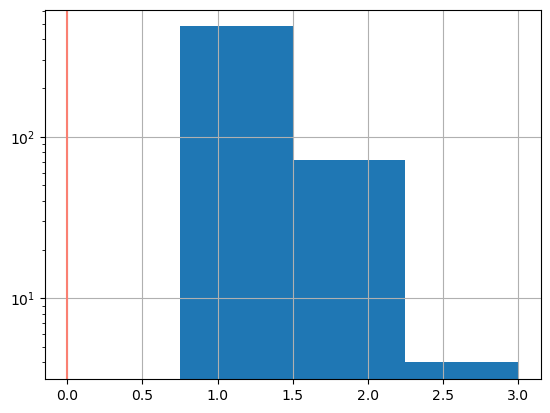

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

inpathlist = snakemake.input["tsv"]
# Read all dataframes and concatenate them
df = pd.concat((pd.read_csv(filename, sep = '\t', usecols=['Query_name', 'Barcode']) for filename in inpathlist), ignore_index = True)

assert len(df) == len(df['Query_name'].unique()) # Read names are unique after concatenating dataframes

# Make a dataframe with the barcodes and a list of read ids corresponding to those barcodes
df_list = (df
           .groupby('Barcode')['Query_name'].apply(list).reset_index() # Group reads per barcode
           .assign(Counts = lambda df_: df_['Query_name'].str.len()) # Count number of reads per unique bc
          )


# Plot the histogram
# TODO: Clean it up!
max_counts = df_list['Counts'].max()
vmin, vmax = (0, int(np.percentile(df_list['Counts'], 99.9)))
nbins = max_counts if max_counts < 10 else min(200, vmax - vmin)
df_list['Counts'].hist(range=(vmin, vmax), bins = nbins)
plt.yscale("log")
plt.axvline(snakemake.params["threshold"], color="salmon")
plt.savefig(snakemake.output["barcode_hist"], dpi=150)

# Threshold barcodes by depth
df_list = (df_list
           .loc[df_list['Counts'] >= snakemake.params["threshold"]]
           .reset_index(drop=True) # Reset index after filtering
           .reset_index() # Reset index to generate the Barcode_id
           .rename(columns={'index': 'Barcode_id'})
          )

# Save 
df_list.to_csv(snakemake.output["inv_barcode_codebook"], sep='\t', index=False)

## D

In [59]:
SCRATCH_PATH = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/"
# tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_2_02.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_5_05.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_3_03.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_6_06.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_4_04.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_1_01.tsv']

tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_1_01.tsv']

inv_barcode_codebook = SCRATCH_PATH+"graph_output/inv_codebook.tsv"
tsv=tsv_list#SCRATCH_PATH+"graph_output/tube_1_01.tsv" #tsv_list,

DEPTH_THRESHOLD = 0

class Snakemake():
    def __init__(self):
        self.input = {}
        self.output = {}
        self.params = {}
        self.input["tsv"] = tsv
        self.output["barcode_hist"] = SCRATCH_PATH+"graph_output/barcode_counts.png"
        self.output["barcode_counts_dict"] = SCRATCH_PATH+"graph_output/barcode_counts_dict.pkl"
        self.output["inv_barcode_codebook"] = SCRATCH_PATH+"graph_output/inv_codebook.tsv"
        
        self.params["threshold"] = DEPTH_THRESHOLD
        
snakemake = Snakemake()

198 ms ± 5.82 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


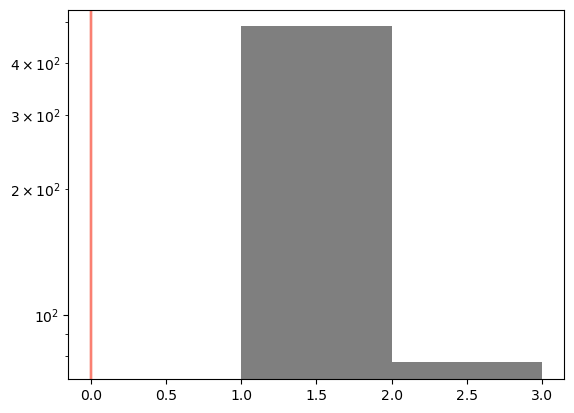

In [61]:
%%timeit
import csv
import numpy as np
import pickle as pkl

from matplotlib import pyplot as plt


def get_barcode_codebook(barcode_dict, final_barcode_idx):
    barcode_codebook = {}
    inv_barcode_codebook = {i: [] for i in range(len(final_barcode_idx))}
    for key, val in barcode_dict.items():
        if val in final_barcode_idx.keys():
            barcode_codebook[key] = final_barcode_idx[val]
            inv_barcode_codebook[final_barcode_idx[val]].append(key)
        else:
            barcode_codebook[key] = None
    return barcode_codebook, inv_barcode_codebook


### Get Barcode Histogram ###
inpathlist = snakemake.input["tsv"]

barcode_dict = {}
for filepath in inpathlist:
    with open(filepath, "r") as infile:
        next(infile)
        for line in infile:
            data = line.split("\t")
            barcode_dict[data[0]] = data[1]

barcode_arr = np.array(list(barcode_dict.values()))
unique, counts = np.unique(barcode_arr, return_counts=True)
barcode_counts_dict = {unique[i]: counts[i] for i in range(len(unique))}

with open(snakemake.output["barcode_counts_dict"], "wb") as f:
    pkl.dump(barcode_counts_dict, f, pkl.HIGHEST_PROTOCOL)

vmin, vmax = (0, int(np.percentile(counts, 99.9)))
nbins = min(200, vmax - vmin)

plt.hist(counts, range=(vmin, vmax), bins=nbins)
plt.yscale("log")
plt.axvline(snakemake.params["threshold"], color="salmon")
plt.savefig(snakemake.output["barcode_hist"], dpi=150)

### Threshold Barcodes and Create Index ###

final_barcode_arr = unique[counts >= snakemake.params["threshold"]]
final_barcode_idx = dict(zip(final_barcode_arr, range(len(final_barcode_arr))))
rev_final_barcode_idx = {val: key for key, val in final_barcode_idx.items()}
_, inv_barcode_codebook = get_barcode_codebook(barcode_dict, final_barcode_idx)
# inv_barcode_codebook = {str(key):str(",".join(val)) for key,val in inv_barcode_codebook.items()}
inv_barcode_codebook = [
    {"barcodeid": key, "readlist": val, "barcode": rev_final_barcode_idx[key]}
    for key, val in inv_barcode_codebook.items()
]

keys = ["barcodeid", "readlist", "barcode"]
with open(snakemake.output["inv_barcode_codebook"], "w") as outfile:
    dict_writer = csv.DictWriter(outfile, keys, delimiter="\t")
    dict_writer.writeheader()
    dict_writer.writerows(inv_barcode_codebook)


# group_barcodes.py

In [2]:
SCRATCH_PATH = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/"
tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_2_02.tsv', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_5_05.tsv', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_3_03.tsv', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_6_06.tsv', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_4_04.tsv', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_1_01.tsv']
fastq_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_2_02.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_5_05.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_3_03.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_6_06.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_4_04.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_1_01.fastq']

inv_barcode_codebook = SCRATCH_PATH+"graph_output/inv_codebook.tsv"
tsv=tsv_list#SCRATCH_PATH+"graph_output/tube_1_01.tsv" #tsv_list,
fastq= fastq_list#SCRATCH_PATH+"reads/tube_1_01.fastq"#fastq_list,
gfa=SCRATCH_PATH+"ref.gfa"

CHUNK_SIZE = 50
N_SUBSAMPLES = [None]

class Snakemake():
    def __init__(self):
        self.input = {}
        self.output = {}
        self.params = {}
        self.input["inv_barcode_codebook"] = inv_barcode_codebook
        self.input["tsv"] = tsv
        self.input["fastq"] = fastq
        self.input["gfa"] = gfa
        self.output["readgroups"] = SCRATCH_PATH+"readgroups"
        self.output["grouprefs"] = SCRATCH_PATH+"grouprefs"
        
        self.params["chunksize"] = CHUNK_SIZE
        self.params["subsample_list"] = N_SUBSAMPLES
        
snakemake = Snakemake()

## L

In [187]:
# I need to generate references for all the graphaligner paths
SCRATCH_PATH = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/"

# tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_2_02.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_5_05.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_3_03.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_6_06.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_4_04.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv']

# fastq_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_2_02.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_5_05.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_3_03.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_6_06.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_4_04.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_1_01.fastq']

tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv']
fastq_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/reads/tube_1_01.fastq']

inv_barcode_codebook = SCRATCH_PATH+"graph_output/inv_codebook.tsv"
tsv=tsv_list#SCRATCH_PATH+"graph_output/tube_1_01.tsv" #tsv_list,
fastq= fastq_list#SCRATCH_PATH+"reads/tube_1_01.fastq"#fastq_list,
gfa=SCRATCH_PATH+"ref_lLAG2.gfa"

CHUNK_SIZE = 50
N_SUBSAMPLES = [None]

class Snakemake():
    def __init__(self):
        self.input = {}
        self.output = {}
        self.params = {}
        self.input["inv_barcode_codebook"] = inv_barcode_codebook
        self.input["tsv"] = tsv
        self.input["fastq"] = fastq
        self.input["gfa"] = gfa
        self.output["readgroups"] = SCRATCH_PATH+"readgroups"
        self.output["grouprefs"] = SCRATCH_PATH+"grouprefs"
        
        self.params["chunksize"] = CHUNK_SIZE
        self.params["subsample_list"] = N_SUBSAMPLES
        
snakemake = Snakemake()

In [191]:
import ast
from Bio import SeqIO
import os
import shutil

## Get Segments to sequences from graph reference
with open(snakemake.input['gfa'], 'r') as infile:
    x = np.array(infile.readlines())
    
last_row_of_seq = np.argwhere(np.diff([not line.startswith('S') for line in x[1:]]))[0][0] + 1

df_segs_to_seq = (pd
                  .read_csv(snakemake.input['gfa'],
                            sep='\t',
                            nrows= last_row_of_seq,
                            skiprows = 1,
                            header=None,
                            names = [0, 'seg_name', 'seg_sequence'],
                            usecols=['seg_name', 'seg_sequence'],
                            index_col='seg_name')
                  .iloc[:,0]
                 )

#######################
## Read all the tsvs with the read ids and paths. This is faster than loading the cigar dict!
inpathlist = snakemake.input["tsv"]
# Read all dataframes and concatenate them
df_reads = pd.concat((pd
                      .read_csv(filename,
                                sep = '\t',
                                usecols=['Query_name', 'Barcode', 'Strand', 'Path_matching'])
                      .astype({'Strand':'category'})
                     
                for filename in inpathlist),
               ignore_index = True)

########################
## Get barcode df. Each cell in the 'Query_name' col contains the list of reads corresponding to a given bc
df_codebook = pd.read_csv(snakemake.input['inv_barcode_codebook'], sep = '\t')

df_codebook = (df_codebook
               .astype({'Barcode_id': 'int32', 'Counts': 'int32'})
               .assign(Query_name = lambda df_:df_['Query_name']
                       .astype(str)
                       .apply(ast.literal_eval))
               .assign(First_read = lambda df_:df_['Query_name'].str[0])
              )

# Merge read seq
df_codebook = (df_codebook
               .merge(df_reads[['Query_name', 'Strand', 'Path_matching']],
                      left_on='First_read',
                      right_on='Query_name',
                      how='left',
                      suffixes=('','_y'),
                      validate='one_to_many')
               .drop(columns=['Query_name_y'])
              )

# Get seg_list # TODO: DO IT ON THE FIRST get_barcodes.py. FASTEST WAY?
df_codebook.loc[df_codebook['Strand'] == '+', 'Seg_list'] = df_codebook.loc[df_codebook['Strand'] == '+', 'Path_matching'].str.split('>').str[1:]
df_codebook.loc[df_codebook['Strand'] == '-', 'Seg_list'] = df_codebook.loc[df_codebook['Strand'] == '-', 'Path_matching'].str.split('<').str[1:].str[::-1]

def generate_reference(seg_list): # Not pass df_segs_to_seq
    return ''.join(list(map(lambda segment: df_segs_to_seq.loc[segment], seg_list)))

# Get ref_seq
df_codebook['ref_seq'] = df_codebook['Seg_list'].apply(generate_reference)


#############
# df having name of read and read sequence (from fastq)
def parse_fastq_files(fastqlist):
    '''
    fastqlist (list): List of fastq filenames with the reads
    
    Returns
        pd.DataFrame: df with read_name as index and read_sequence
    '''
    record_dict = {}
    for i, fastqfile in enumerate(fastqlist):
        read_name_list = []
        read_list = []
        with open(fastqfile, "r") as infile:
            for i, line in enumerate(infile):
                if i % 4 == 0:
                    read_name_list.append(
                        line.rstrip().replace(" ", "_")[1:]
                    )  ##changed to include whole readname, whitespace replaced with underscore
                elif i % 4 == 1:
                    read_list.append(line.rstrip())
        working_dict = dict(zip(read_name_list, read_list))
        record_dict.update(working_dict)
        del working_dict
    
    return pd.DataFrame.from_dict(record_dict, orient='index', columns=['Read_sequence'])

df_reads = parse_fastq_files(fastqlist)

readgroup_path = snakemake.output["readgroups"]
if os.path.exists(readgroup_path):
    shutil.rmtree(readgroup_path)
os.makedirs(readgroup_path)

groupref_path = snakemake.output["grouprefs"]
if os.path.exists(groupref_path):
    shutil.rmtree(groupref_path)
os.makedirs(groupref_path)

chunksize = snakemake.params["chunksize"]
subsample_list = snakemake.params["subsample_list"]


# TODO INCLUDE SUBSAMPLING, PASS DFS
def write_reference_to_file(barcode_id, ref_seq, read_id_list):
    
    # Get string for reference (fasta)
    ref_str = ''
    ref_str = '>group_' + str(barcode_id) + '\n'
    ref_str += ref_seq + '\n'

    subsample = None

    intermediate_path = (
        '/subsample='
        + str(subsample)
        + '/chunk_'
        + str(barcode_id // chunksize)   
    )
    
    refchunkpath = (
        groupref_path
        + intermediate_path
    )

    if not os.path.exists(refchunkpath):
                os.makedirs(refchunkpath)

    ref_fasta_path = refchunkpath + '/group_' + str(barcode_id) + '.fasta'

    with open(ref_fasta_path, 'w') as outfile:
        outfile.write(ref_str)
        
    readchunkpath = (
        readgroup_path
        + intermediate_path
    )
    
    # if else subsampel
    if not os.path.exists(readchunkpath):
        os.makedirs(readchunkpath)
    
    read_str = ''
    for read_id in read_id_list:
        read_seq = df_reads.loc[read_id, 'Read_sequence']
        read_str += '@' + read_id + '\n'
        read_str += read_seq + '\n'
    
    with open(readchunkpath + '/group_' + str(barcode_id) + '.fastq', 'w') as outfile:
        outfile.write(read_str)

# Write files for each barcode (a reference file and all the reads)
_ = df_codebook.apply(lambda df_: write_reference_to_file(df_['Barcode_id'], df_['ref_seq'], df_['Query_name']), axis=1)

## D

In [113]:
# I need to generate references for all the graphaligner paths
SCRATCH_PATH = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/"

# tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_2_02.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_5_05.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_3_03.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_6_06.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_4_04.tsv',
#             '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv']

# fastq_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_2_02.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_5_05.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_3_03.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_6_06.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_4_04.fastq',
#               '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_1_01.fastq']

tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/graph_output/tube_1_01.tsv']
fastq_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_1_01.fastq']

inv_barcode_codebook = SCRATCH_PATH+"graph_output/inv_codebook.tsv"
tsv=tsv_list#SCRATCH_PATH+"graph_output/tube_1_01.tsv" #tsv_list,
fastq= fastq_list#SCRATCH_PATH+"reads/tube_1_01.fastq"#fastq_list,
gfa=SCRATCH_PATH+"ref_lLAG2.gfa"

CHUNK_SIZE = 50
N_SUBSAMPLES = [None]

class Snakemake():
    def __init__(self):
        self.input = {}
        self.output = {}
        self.params = {}
        self.input["inv_barcode_codebook"] = inv_barcode_codebook
        self.input["tsv"] = tsv
        self.input["fastq"] = fastq
        self.input["gfa"] = gfa
        self.output["readgroups"] = SCRATCH_PATH+"readgroups"
        self.output["grouprefs"] = SCRATCH_PATH+"grouprefs"
        
        self.params["chunksize"] = CHUNK_SIZE
        self.params["subsample_list"] = N_SUBSAMPLES
        
snakemake = Snakemake()

In [114]:
%%timeit
import csv
import ast
import os
import shutil
import numpy as np
import pandas as pd

from Bio import SeqIO

from matplotlib import pyplot as plt

def make_seg_dict(gfafile):
    segment_dict = {}
    with open(gfafile, "r") as infile:
        for line in infile:
            if line[0] == "S":
                splitline = line.split("\t")
                segment_dict[splitline[1]] = splitline[2][:-1]
    return segment_dict


def generate_reference(cigar, segment_dict):
    if cigar[0] == "+":
        traversal = cigar[3].split(">")[1:]
        ref = "".join(list(map(lambda seg: segment_dict[seg], traversal)))
    elif cigar[0] == "-":
        traversal = cigar[3].split("<")[1:][::-1]
        ref = "".join(list(map(lambda seg: segment_dict[seg], traversal)))
    return ref


### Get Barcode to Read Map ###

inv_codebook_path = snakemake.input["inv_barcode_codebook"]
tsv_paths = snakemake.input["tsv"]
inv_barcode_codebook = {}
codebook_data = pd.read_csv(inv_codebook_path, delimiter="\t")
for _, row in codebook_data.iterrows():
    inv_barcode_codebook[int(row["barcodeid"])] = ast.literal_eval(row["readlist"])

cigar_dict = {}
for filepath in tsv_paths:
    with open(filepath, "r") as csvfile:
        reader = csv.DictReader(csvfile, delimiter="\t")
        for row in reader:
            cigar_dict[row["readname"]] = ast.literal_eval(row["cigar"])

### Make Segment Dictionary ###
gfafile = snakemake.input["gfa"]
seg_dict = make_seg_dict(gfafile)

import psutil

### Make fastq lookup ###
fastqlist = snakemake.input["fastq"]
record_dict = {}
for i, fastqfile in enumerate(fastqlist):
    read_name_list = []
    read_list = []
    with open(fastqfile, "r") as infile:
        for i, line in enumerate(infile):
            if i % 4 == 0:
                read_name_list.append(
                    line.rstrip().replace(" ", "_")[1:]
                )  ##changed to include whole readname, whitespace replaced with underscore
            elif i % 4 == 1:
                read_list.append(line.rstrip())
    working_dict = dict(zip(read_name_list, read_list))
    record_dict.update(working_dict)
    del working_dict

readgroup_path = snakemake.output["readgroups"]
if os.path.exists(readgroup_path):
    shutil.rmtree(readgroup_path)
os.makedirs(readgroup_path)

groupref_path = snakemake.output["grouprefs"]
if os.path.exists(groupref_path):
    shutil.rmtree(groupref_path)
os.makedirs(groupref_path)

chunksize = snakemake.params["chunksize"]
subsample_list = snakemake.params["subsample_list"]

for key, val in inv_barcode_codebook.items():

    ref_str = ""
    ref_seq = generate_reference(cigar_dict[val[0]], seg_dict)
    ref_str += ">group_" + str(key) + "\n"
    ref_str += ref_seq + "\n"

    for subsample in subsample_list:
        refchunkpath = (
            groupref_path
            + "/subsample="
            + str(subsample)
            + "/chunk_"
            + str(key // chunksize)
        )
        if not os.path.exists(refchunkpath):
            os.makedirs(refchunkpath)

        with open(refchunkpath + "/group_" + str(key) + ".fasta", "w") as outfile:
            outfile.write(ref_str)

        readchunkpath = (
            readgroup_path
            + "/subsample="
            + str(subsample)
            + "/chunk_"
            + str(key // chunksize)
        )

        if subsample == None:
            subsampled_reads = val
        else:
            subsampled_reads = list(
                np.random.choice(val, size=subsample, replace=False)
            )

        if not os.path.exists(readchunkpath):
            os.makedirs(readchunkpath)

        out_str = ""

        for read_name in subsampled_reads:
            seq_record = record_dict[read_name]
            out_str += "@" + str(read_name) + "\n"
            out_str += seq_record + "\n"

        with open(readchunkpath + "/group_" + str(key) + ".fastq", "w") as outfile:
            outfile.write(out_str)


25.9 s ± 2.18 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [ ]:
# Check reads from the first barcode (barcodeid = 0)

In [520]:
len(luis_keys)

9300

In [521]:
len(daniel_keys)

9300

In [508]:
len(sequences)

13380

In [504]:
len(sequences)

13380

In [506]:
fastqlist

['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_2_02.fastq',
 '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_5_05.fastq',
 '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_3_03.fastq',
 '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_6_06.fastq',
 '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_4_04.fastq',
 '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_1_01.fastq']

In [472]:
del record_dict

In [505]:
len(record_dict)

9300

In [ ]:
# I need to generate references for all the graphaligner paths
SCRATCH_PATH = "/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/"
tsv_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_2_02.tsv',
            '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_5_05.tsv',
            '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_3_03.tsv',
            '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_6_06.tsv',
            '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_4_04.tsv',
            '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/graph_output/tube_1_01.tsv']
fastq_list = ['/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_2_02.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_5_05.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_3_03.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_6_06.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_4_04.fastq', '/home/lag36/scratch/lag36/2023-10-24_lDE2-nanopore/dict_version/reads/tube_1_01.fastq']

inv_barcode_codebook = SCRATCH_PATH+"graph_output/inv_codebook.tsv"
tsv=tsv_list#SCRATCH_PATH+"graph_output/tube_1_01.tsv" #tsv_list,
fastq= fastq_list#SCRATCH_PATH+"reads/tube_1_01.fastq"#fastq_list,
gfa=SCRATCH_PATH+"ref.gfa"

CHUNK_SIZE = 50
N_SUBSAMPLES = [None]

class Snakemake():
    def __init__(self):
        self.input = {}
        self.output = {}
        self.params = {}
        self.input["inv_barcode_codebook"] = inv_barcode_codebook
        self.input["tsv"] = tsv
        self.input["fastq"] = fastq
        self.input["gfa"] = gfa
        self.output["readgroups"] = SCRATCH_PATH+"readgroups"
        self.output["grouprefs"] = SCRATCH_PATH+"grouprefs"
        
        self.params["chunksize"] = CHUNK_SIZE
        self.params["subsample_list"] = N_SUBSAMPLES
        
snakemake = Snakemake()